## scGPT benchmarking

In this notebook we test our best scGPT pipeline with several different cases/patients and several different cells to understand how performance varies across all of these.

In [1]:
# 1 — Paths and settings: edit this cell only to choose specimens/run size.
from pathlib import Path
from datetime import datetime, timezone
import gc
import gzip
import hashlib
import importlib.metadata
import importlib.util
import json
import platform
import sys
import time

import anndata as ad
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.io import mmread
from threadpoolctl import threadpool_limits
import torch
from IPython.display import display

ROOT = Path.home() / "scgpt-cna"
LAB_ROOT = Path("/home/akash1/projects/rrg-tperkins/dgladish/Projects/MSc/benchmarking_spatial_scale")
META = LAB_ROOT / "metadata/sample_md.tsv"
GDC_ROOT = LAB_ROOT / "GDC-data"
MODEL = ROOT / "models/whole-human"
HELPER = ROOT / "notebooks/scgpt_session/scgpt_session.py"
HISTORICAL = ROOT / "sanity_check/reference_4068d67/scgpt"
CENSUS_ANNOTATION = ROOT / "sanity_check/data/census_proximal_tubule_256/reference_raw.h5ad"

# Same diagnosis initially; distinct patients. Edit/add IDs after inspecting metadata.
SAMPLE_IDS = ["C3N-00148-01", "C3L-00359-01", "C3L-01287-01"]
# For example, add "C3L-03405-01" later for a brain/glioblastoma specimen.

# If automatic discovery finds multiple matrices, explicitly set a directory here.
MATRIX_DIR_OVERRIDES = {}       # {"sample-id": Path("/absolute/path/to/mex_directory")}
COPYKAT_OVERRIDES = {}         # Optional: {"sample-id": Path("/absolute/path/to/prediction.txt")}

MODE = "full"                # Change to "full" after checking the pilot.
assert MODE in {"pilot", "full"}
SPLIT_SEED = 42
N_REFERENCE = 128
N_EVALUATION = 128
MASK_FRACTION = 0.25
MASK_SEEDS = [42] if MODE == "pilot" else [42, 43, 44, 45]
MAX_EVALUATED = 8 if MODE == "pilot" else N_EVALUATION
ACTIVE_SAMPLE_IDS = SAMPLE_IDS[:1] if MODE == "pilot" else SAMPLE_IDS
RUN_SHUFFLED = True
SAVE_QUERY_PREDICTIONS = True  # Compressed per-mask files; no dense expression export.
N_THREADS = 4
torch.set_num_threads(N_THREADS)

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + MODE
RUN_DIR = ROOT / "multicase_expression/results" / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)

required = [META, HELPER, HISTORICAL / "preprocess.py",
            HISTORICAL / "data_collator.py", CENSUS_ANNOTATION]
required += [MODEL / f for f in ["args.json", "vocab.json", "best_model.pt"]]
for path in required:
    assert path.is_file(), f"Required existing file not found: {path}"
print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "| threads:", torch.get_num_threads())
print("Mode:", MODE, "| active specimens:", ACTIVE_SAMPLE_IDS)
print("Output:", RUN_DIR)


Python: /home/akash1/scgpt-cna/.venv-scgpt/bin/python
PyTorch: 2.2.2+cpu | threads: 4
Mode: full | active specimens: ['C3N-00148-01', 'C3L-00359-01', 'C3L-01287-01']
Output: /home/akash1/scgpt-cna/multicase_expression/results/20261105T212842316783Z_full


In [2]:
# 2 — Pin the preprocessing binding and load every checkpoint tensor strictly.
def import_file(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    assert Path(module.__file__).resolve() == Path(path).resolve()
    return module

session = import_file("multicase_verified_session", HELPER)
historical = import_file("multicase_historical_preprocess", HISTORICAL / "preprocess.py")
historical_collator = import_file(
    "scgpt._multicase_historical_collator", HISTORICAL / "data_collator.py"
)
historical_collator.binning = historical.binning
assert historical_collator.binning is historical.binning
assert historical._digitize.__defaults__ == ("one",), "Unexpected tie rule."

model, loaded_vocab, config = session.load_model(MODEL)
model = model.cpu().eval()
vocab = loaded_vocab.get_stoi()
assert config["n_bins"] == 51 and config["max_seq_len"] == 1200
pad_id = vocab[config.get("pad_token", "<pad>")]
cls_id = vocab["<cls>"]
pad_value = config.get("pad_value", -2)
collator = historical_collator.DataCollator(
    do_padding=True, pad_token_id=pad_id, pad_value=pad_value,
    do_mlm=True, do_binning=True, mlm_probability=MASK_FRACTION,
    mask_value=config.get("mask_value", -1), max_length=config["max_seq_len"],
    sampling=True, keep_first_n_tokens=1, data_style="both",
)
print("Helper:", session.__file__)
print("Historical tie rule:", historical._digitize.__defaults__)

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024**2), b""):
            digest.update(block)
    return digest.hexdigest()

run_manifest = {
    "run_id": RUN_ID, "mode": MODE, "sample_ids": ACTIVE_SAMPLE_IDS,
    "split_seed": SPLIT_SEED, "n_reference": N_REFERENCE,
    "n_evaluation_reserved": N_EVALUATION, "n_evaluated": MAX_EVALUATED,
    "mask_seeds": MASK_SEEDS, "mask_fraction": MASK_FRACTION,
    "run_shuffled": RUN_SHUFFLED, "config": config,
    "helper_path": str(HELPER), "helper_sha256": sha256(HELPER),
    "checkpoint_sha256": sha256(MODEL / "best_model.pt"),
    "vocab_sha256": sha256(MODEL / "vocab.json"),
    "historical_commit": "4068d67caaac1e28d56964da68e0214817e38428",
    "historical_preprocess_sha256": sha256(HISTORICAL / "preprocess.py"),
    "historical_collator_sha256": sha256(HISTORICAL / "data_collator.py"),
    "census_annotation_path": str(CENSUS_ANNOTATION),
    "versions": {p: importlib.metadata.version(p) for p in
                 ["torch", "scgpt", "anndata", "numpy", "scipy", "pandas"]},
    "python": sys.version, "platform": platform.platform(),
    "baseline_scope": "Separate reference cells within each specimen; positive-gene bin means",
    "qc_policy": "No new biological QC exclusions; require enough detected model genes for >=1 query",
    "limitations": [
        "Current specimen has already been explored; new patients are replication data",
        "Only detected genes are queried; zero measurements are not evaluated",
        "Full-profile quantile boundaries use hidden expression values",
        "CopyKAT categories are predictions, not cell-type or malignancy truth",
        "Masks and queried genes within a patient are not independent patients",
        "Pinned preprocessing is verified; exact released checkpoint training commit is unconfirmed",
    ],
}
(RUN_DIR / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2))


/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/model.py:21: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")
/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/multiomic_model.py:19: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")


Strict load: 163 checkpoint tensors; no omitted tensors.
Helper: /home/akash1/scgpt-cna/notebooks/scgpt_session/scgpt_session.py
Historical tie rule: ('one',)


3573

In [3]:
# 3 — Inspect sample identities and discover sparse 10x files, without loading counts.
metadata = pd.read_csv(META, sep="\t", dtype=str)
assert metadata["sample_id"].is_unique
missing = set(SAMPLE_IDS) - set(metadata["sample_id"])
assert not missing, f"IDs absent from sample metadata: {sorted(missing)}"
selected_metadata = metadata.set_index("sample_id").loc[SAMPLE_IDS].reset_index()
assert selected_metadata["case_id"].is_unique, "Choose one specimen per patient initially."

def sidecar(directory, stem):
    candidates = [directory / stem, directory / (stem + ".gz")]
    found = [p for p in candidates if p.is_file()]
    assert len(found) == 1, f"Expected one {stem}(.gz) in {directory}; found {found}"
    return found[0]

def discover_sample(record):
    sid, case = record["sample_id"], record["case_id"]
    sample_dir = GDC_ROOT / case / sid
    assert sample_dir.is_dir(), f"Missing sample directory: {sample_dir}"
    if sid in MATRIX_DIR_OVERRIDES:
        matrix_dir = Path(MATRIX_DIR_OVERRIDES[sid])
    else:
        # Search only this specimen's single_cell subtree; ignore dense CSVs/archives.
        candidates = sorted({p.parent for p in (sample_dir / "single_cell").rglob("matrix.mtx*")
                             if p.name in {"matrix.mtx", "matrix.mtx.gz"}})
        filtered = [p for p in candidates if "filtered" in str(p).lower()
                    and "raw_feature" not in str(p).lower()]
        if filtered:
            candidates = filtered
        assert len(candidates) == 1, (
            f"Ambiguous/missing MEX directory for {sid}: {candidates}. "
            "Set MATRIX_DIR_OVERRIDES explicitly. Do not choose a raw droplet matrix."
        )
        matrix_dir = candidates[0]
    ck = ([Path(COPYKAT_OVERRIDES[sid])] if sid in COPYKAT_OVERRIDES else
          sorted((sample_dir / "single_cell").rglob("*copykat_prediction.txt")))
    assert len(ck) <= 1, f"Multiple CopyKAT files for {sid}; set COPYKAT_OVERRIDES."
    if ck:
        assert ck[0].is_file()
    return {
        **record, "sample_directory": str(sample_dir),
        "matrix_file": str(sidecar(matrix_dir, "matrix.mtx")),
        "features_file": str(sidecar(matrix_dir, "features.tsv")),
        "barcodes_file": str(sidecar(matrix_dir, "barcodes.tsv")),
        "copykat_file": str(ck[0]) if ck else "",
    }

manifest = pd.DataFrame([discover_sample(r) for r in selected_metadata.to_dict("records")])
display(manifest[["case_id", "sample_id", "primary_site",
                  "diagnoses.0.primary_diagnosis", "wgd_status", "matrix_file"]])
manifest.to_csv(RUN_DIR / "sample_manifest.tsv", sep="\t", index=False)
print("All selected specimens have an unambiguous sparse matrix.")


,case_id,sample_id,primary_site,diagnoses.0.primary_diagnosis,wgd_status,matrix_file
0,C3N-00148,C3N-00148-01,Kidney,"Renal cell carcinoma, NOS",WGD+,/home/akash1/projects/rrg-tperkins/dgladish/Pr...
1,C3L-00359,C3L-00359-01,Kidney,"Renal cell carcinoma, NOS",WGD+,/home/akash1/projects/rrg-tperkins/dgladish/Pr...
2,C3L-01287,C3L-01287-01,Kidney,"Renal cell carcinoma, NOS",WGD-,/home/akash1/projects/rrg-tperkins/dgladish/Pr...


All selected specimens have an unambiguous sparse matrix.


In [4]:
# 4 — Load the shared annotation map; define sparse loading and harmonization.
# Census counts are never read here. Feature IDs connect alternative gene symbols.
census_annotation = ad.read_h5ad(CENSUS_ANNOTATION, backed="r")
census_var = census_annotation.var[["feature_id", "feature_name"]].copy()
census_annotation.file.close()
del census_annotation

def base_ids(values):
    # Strip only terminal Ensembl version numbers. Keep PAR_Y identities separate.
    return pd.Series(values, dtype="string").str.replace(r"\.\d+$", "", regex=True)

census_var["ensembl_base"] = base_ids(census_var["feature_id"].to_numpy()).to_numpy()
symbol_counts = census_var.groupby("ensembl_base")["feature_name"].nunique()
unambiguous_ids = symbol_counts.index[symbol_counts.eq(1)]
id_to_symbol = (
    census_var.loc[census_var["ensembl_base"].isin(unambiguous_ids)]
    .drop_duplicates("ensembl_base").set_index("ensembl_base")["feature_name"]
)
print("Unambiguous annotation IDs:", len(id_to_symbol))
print("Ambiguous IDs excluded:", int(symbol_counts.gt(1).sum()))

def load_lab_sample(record):
    started = time.perf_counter()
    features = pd.read_csv(record["features_file"], sep="\t", header=None, dtype=str)
    barcodes = pd.read_csv(record["barcodes_file"], sep="\t", header=None, dtype=str)[0]
    assert features.shape[1] >= 3 and barcodes.is_unique
    with threadpool_limits(limits=N_THREADS):
        matrix_path = Path(record["matrix_file"])
        if matrix_path.suffix == ".gz":
            with gzip.open(matrix_path, "rb") as stream:
                raw = mmread(stream).T.tocsr()
        else:
            raw = mmread(matrix_path).T.tocsr()
    raw.sum_duplicates(); raw.eliminate_zeros(); raw.sort_indices()
    assert raw.shape == (len(barcodes), len(features))
    assert np.isfinite(raw.data).all() and (raw.data >= 0).all()
    assert np.equal(raw.data, np.rint(raw.data)).all(), "Expected integer UMI counts."
    gex = features[2].eq("Gene Expression").to_numpy()
    assert gex.any()
    raw = raw[:, gex].tocsr()
    var = features.loc[gex, [0, 1, 2]].reset_index(drop=True)
    var.columns = ["gene_id", "gene_symbol", "feature_type"]
    assert var["gene_id"].is_unique, "Duplicate feature IDs require an explicit resolution."
    var["ensembl_base"] = base_ids(var["gene_id"]).to_numpy()
    var["census_symbol"] = var["ensembl_base"].map(id_to_symbol)
    # Prefer a recognized ID-matched Census symbol; otherwise retain a recognized lab symbol.
    mapped_ok = var["census_symbol"].isin(vocab)
    var["model_symbol"] = var["census_symbol"].where(mapped_ok, var["gene_symbol"])
    original_keep = var["gene_symbol"].isin(vocab) & ~var["gene_symbol"].duplicated()
    recognized = var["model_symbol"].isin(vocab)
    keep = recognized & ~var["model_symbol"].duplicated(keep="first")
    columns = np.flatnonzero(keep.to_numpy())
    gene_info = var.iloc[columns].reset_index(drop=True)
    gene_ids = np.array([vocab[s] for s in gene_info["model_symbol"]], dtype=np.int64)
    assert len(gene_ids) == len(np.unique(gene_ids))
    matrix = raw[:, columns].tocsr().astype(np.float32)
    matrix.eliminate_zeros(); matrix.sort_indices()

    obs = pd.DataFrame(index=pd.Index(barcodes.to_numpy(), name="barcode"))
    obs["cell_index"] = np.arange(len(obs))
    obs["case_id"], obs["sample_id"] = record["case_id"], record["sample_id"]
    obs["cell_id"] = record["sample_id"] + ":" + obs.index.astype(str)
    obs["tissue"] = record["primary_site"]
    obs["diagnosis"] = record["diagnoses.0.primary_diagnosis"]
    obs["sample_wgd_status"] = record["wgd_status"]
    obs["cell_type"] = "unassigned"
    obs["malignant_status"] = "unresolved"
    obs["total_counts"] = np.asarray(raw.sum(axis=1)).ravel()
    obs["detected_genes"] = raw.getnnz(axis=1)
    obs["model_detected_genes"] = matrix.getnnz(axis=1)
    obs["model_total_counts"] = np.asarray(matrix.sum(axis=1)).ravel()
    obs["model_count_fraction"] = obs["model_total_counts"] / obs["total_counts"].replace(0, np.nan)
    mt_columns = var["gene_symbol"].str.startswith("MT-").to_numpy()
    obs["pct_counts_mt"] = (100 * np.asarray(raw[:, mt_columns].sum(axis=1)).ravel()
                            / obs["total_counts"].replace(0, np.nan))
    ones = raw.copy()
    ones.data = (ones.data == 1).astype(np.int8)
    obs["fraction_count_one"] = (np.asarray(ones.sum(axis=1)).ravel()
                                  / obs["detected_genes"].replace(0, np.nan))
    del ones

    # Full-profile, deterministic model-bin summaries for each cell.
    model_singletons, occupied, dominant, singleton_bin = [], [], [], []
    for i in range(matrix.shape[0]):
        counts = matrix.data[matrix.indptr[i]:matrix.indptr[i + 1]]
        if not len(counts):
            model_singletons.append(np.nan); occupied.append(0)
            dominant.append(np.nan); singleton_bin.append(np.nan)
            continue
        labels = np.asarray(historical.binning(counts.copy(), n_bins=51))
        _, frequencies = np.unique(labels, return_counts=True)
        one = counts == 1
        model_singletons.append(float(one.mean()))
        occupied.append(len(frequencies))
        dominant.append(float(frequencies.max() / len(labels)))
        singleton_bin.append(float(labels[one][0]) if one.any() else np.nan)
    obs["model_fraction_count_one"] = model_singletons
    obs["occupied_bins"] = occupied
    obs["dominant_bin_fraction"] = dominant
    obs["count_one_bin"] = singleton_bin

    obs["copykat_group"] = "missing_from_output"
    unmatched_copykat_barcodes = 0
    if record["copykat_file"]:
        ck = pd.read_csv(record["copykat_file"], sep="\t", dtype=str)
        assert {"cell.names", "copykat.pred"}.issubset(ck.columns)
        assert ck["cell.names"].is_unique
        unmatched_copykat_barcodes = int((~ck["cell.names"].isin(obs.index)).sum())
        obs["copykat_group"] = (ck.set_index("cell.names")["copykat.pred"]
                                 .reindex(obs.index).fillna("missing_from_output"))
    # Clusters, when already downloaded, are retained as cluster IDs, not cell types.
    obs["seurat_cluster"] = "not_available"
    seurat_path = ROOT / "measurement_analysis" / record["sample_id"] / "gdc_secondary_analysis/seurat.analysis.tsv"
    if seurat_path.is_file():
        seurat = pd.read_csv(seurat_path, sep="\t", dtype=str)
        assert {"cell_barcode", "seurat_cluster"}.issubset(seurat.columns)
        assert seurat["cell_barcode"].is_unique
        obs["seurat_cluster"] = (seurat.set_index("cell_barcode")["seurat_cluster"]
                                   .reindex(obs.index).fillna("not_available"))

    total = float(raw.sum())
    report = {
        "sample_id": record["sample_id"], "case_id": record["case_id"],
        "tissue": record["primary_site"], "diagnosis": record["diagnoses.0.primary_diagnosis"],
        "n_cells": matrix.shape[0], "n_raw_features": raw.shape[1],
        "n_model_features": matrix.shape[1],
        "original_symbol_percent_counts": 100 * float(raw[:, original_keep.to_numpy()].sum()) / total,
        "harmonized_percent_counts": 100 * float(matrix.sum()) / total,
        "counts_discarded_duplicate_model_symbols": float(raw[:, (recognized & ~keep).to_numpy()].sum()),
        "copykat_barcodes_absent_from_expression": unmatched_copykat_barcodes,
        "load_and_profile_seconds": time.perf_counter() - started,
    }
    del raw
    gc.collect()
    return matrix, gene_ids, gene_info, obs, report


Unambiguous annotation IDs: 60664
Ambiguous IDs excluded: 0


In [5]:
# 5 — Independent reference cells, native-bin baselines and verified model inputs.
COUNT_GROUPS = ["1 UMI", "2–4 UMIs", "5+ UMIs", "all"]

def umi_groups(values):
    return np.select([values == 1, values <= 4], COUNT_GROUPS[:2], default=COUNT_GROUPS[2])

def reserve_cells(obs):
    minimum_genes = max(2, int(np.ceil(1 / MASK_FRACTION)))
    eligible = np.flatnonzero(obs["model_detected_genes"].to_numpy() >= minimum_genes)
    assert len(eligible) >= N_REFERENCE + N_EVALUATION, (
        f"Only {len(eligible)} eligible cells; need {N_REFERENCE + N_EVALUATION}. "
        "If reducing the budget, use the same setting for all specimens."
    )
    order = np.random.default_rng(SPLIT_SEED).permutation(eligible)
    reference = order[:N_REFERENCE]
    evaluation = order[N_REFERENCE:N_REFERENCE + N_EVALUATION]
    assert not set(reference) & set(evaluation)
    return reference, evaluation

def fit_baseline(matrix, reference):
    # Per-gene mean of native bins CONDITIONAL on detection in a reference cell.
    sums = np.zeros(matrix.shape[1], dtype=np.float64)
    support = np.zeros(matrix.shape[1], dtype=np.int64)
    for i in reference:
        row = matrix.getrow(int(i))
        bins = np.asarray(historical.binning(row.data.copy(), n_bins=51), dtype=float)
        sums[row.indices] += bins
        support[row.indices] += 1
    constant = float(sums.sum() / support.sum())  # Positive cell-gene pairs, not cell means.
    means = np.full(matrix.shape[1], constant)
    np.divide(sums, support, out=means, where=support > 0)
    assert np.isfinite(means).all()
    return means, support, constant

def make_example(matrix, gene_ids, i):
    row = matrix.getrow(int(i))
    return {
        "genes": torch.tensor(np.concatenate(([cls_id], gene_ids[row.indices])), dtype=torch.long),
        "expressions": torch.tensor(np.concatenate(([pad_value], row.data)), dtype=torch.float32),
    }

def make_batch(matrix, gene_ids, evaluation, seed):
    # Always collate ALL reserved cells, even for an eight-cell pilot. The collator
    # chooses lengths using the batch. Fresh examples avoid in-place double binning.
    old_np = np.random.get_state()
    try:
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(seed)
            np.random.seed(seed)
            return collator([make_example(matrix, gene_ids, i) for i in evaluation])
    finally:
        np.random.set_state(old_np)

def verified_input(matrix, gene_ids, batch, j, i):
    vm = batch["pcpt_gene"][j].ne(pad_id)
    qm = batch["gen_gene"][j].ne(pad_id)
    known_ids = batch["pcpt_gene"][j, vm]
    known_values = batch["pcpt_expr"][j, vm]
    query_ids = batch["gen_gene"][j, qm]
    target = batch["gen_expr_target"][j, qm].cpu().numpy().astype(float)
    assert int(known_ids[0]) == cls_id and float(known_values[0]) == pad_value
    assert len(query_ids) and len(known_ids) > 1
    assert cls_id not in query_ids.tolist()
    assert len(known_ids) + len(query_ids) <= config["max_seq_len"]
    row = matrix.getrow(int(i))
    tokens = gene_ids[row.indices]
    positions = {int(t): k for k, t in enumerate(tokens)}
    vi = np.array([positions[t] for t in known_ids[1:].tolist()], dtype=int)
    qi = np.array([positions[t] for t in query_ids.tolist()], dtype=int)
    assert len(set(vi)) == len(vi) and len(set(qi)) == len(qi)
    assert not np.intersect1d(vi, qi).size
    native = np.asarray(historical.binning(row.data.copy(), n_bins=51))
    np.testing.assert_array_equal(native[vi], known_values[1:].cpu().numpy())
    np.testing.assert_array_equal(native[qi], target)
    # Independent quantile/search check, in addition to the historical implementation.
    edges = np.quantile(row.data, np.linspace(0, 1, 50))
    np.testing.assert_array_equal(native, np.searchsorted(edges, row.data, side="right"))
    return known_ids, known_values, query_ids, target, row, vi, qi

@torch.inference_mode()
def predict(known_ids, known_values, query_ids):
    result = model(known_ids.unsqueeze(0), known_values.unsqueeze(0), query_ids.unsqueeze(0))
    return {head: result[head].cpu().numpy().reshape(-1) for head in ["GEP", "MVC"]}

def score_predictions(predictions, target, original_umi, reference_support, metadata):
    groups = umi_groups(original_umi)
    rows = []
    for method, prediction in predictions.items():
        prediction = np.asarray(prediction, dtype=float)
        assert prediction.shape == target.shape and np.isfinite(prediction).all()
        for group in COUNT_GROUPS:
            keep = np.ones(len(target), dtype=bool) if group == "all" else groups == group
            if not keep.any():
                continue
            error = prediction[keep] - target[keep]
            rows.append({
                **metadata, "method": method, "count_group": group,
                "n_queries": int(keep.sum()), "MAE": float(np.abs(error).mean()),
                "MSE": float(np.square(error).mean()), "mean_residual": float(error.mean()),
                "target_mean": float(target[keep].mean()), "target_std": float(target[keep].std()),
                "prediction_mean": float(prediction[keep].mean()),
                "prediction_std": float(prediction[keep].std()),
                "gene_baseline_support_fraction": float((reference_support[keep] > 0).mean()),
            })
    return rows

def summarize_scores(scores):
    # Average masks WITHIN each cell first. A cell has one weight in each group.
    keys = ["sample_id", "case_id", "cell_id", "cell_index", "method", "count_group"]
    per_cell = scores.groupby(keys, as_index=False).agg(
        MSE=("MSE", "mean"), MAE=("MAE", "mean"),
        mean_residual=("mean_residual", "mean"), target_std=("target_std", "mean"),
        prediction_std=("prediction_std", "mean"),
        n_masks=("mask_seed", "nunique"), query_events=("n_queries", "sum"),
    )
    baseline = per_cell.loc[per_cell["method"].eq("gene_mean_plus_offset"),
                           ["cell_id", "count_group", "MSE"]].rename(columns={"MSE": "baseline_MSE"})
    per_cell = per_cell.merge(baseline, on=["cell_id", "count_group"], validate="many_to_one")
    per_cell["MSE_gain"] = per_cell["baseline_MSE"] - per_cell["MSE"]
    summary = per_cell.groupby(["sample_id", "case_id", "count_group", "method"], as_index=False).agg(
        n_cells=("cell_id", "nunique"), mean_MSE=("MSE", "mean"),
        median_MSE=("MSE", "median"), mean_MAE=("MAE", "mean"),
        mean_MSE_gain=("MSE_gain", "mean"), cells_beating_baseline=("MSE_gain", lambda s: int(s.gt(0).sum())),
    )
    # This is a ratio of mean losses, not an average of per-cell percentages.
    summary["mean_baseline_MSE"] = summary["mean_MSE"] + summary["mean_MSE_gain"]
    summary["percent_MSE_reduction"] = 100 * summary["mean_MSE_gain"] / summary["mean_baseline_MSE"]
    return per_cell, summary


In [6]:
# 6 — Run the pilot/full benchmark. Sparse matrices are processed one specimen at a time.
def run_sample(record):
    sid = record["sample_id"]
    destination = RUN_DIR / sid
    destination.mkdir(exist_ok=True)
    started = time.perf_counter()
    print(f"\nLoading {sid}: {record['primary_site']} | {record['diagnoses.0.primary_diagnosis']}", flush=True)
    matrix, gene_ids, gene_info, obs, report = load_lab_sample(record)
    reference, reserved_evaluation = reserve_cells(obs)
    evaluation = reserved_evaluation[:MAX_EVALUATED]
    means, support, constant = fit_baseline(matrix, reference)

    obs["split"] = "unused"
    obs.iloc[reference, obs.columns.get_loc("split")] = "reference"
    obs.iloc[reserved_evaluation, obs.columns.get_loc("split")] = "evaluation_reserved"
    obs["evaluated_this_run"] = obs["cell_index"].isin(evaluation)
    obs.to_csv(destination / "cell_metadata_and_splits.tsv", sep="\t")
    gene_info.assign(gene_token=gene_ids, reference_support=support, reference_mean=means).to_csv(
        destination / "gene_mapping_and_baseline.tsv.gz", sep="\t", index=False)
    report.update({"reference_constant": constant, "n_reference": len(reference),
                   "n_evaluated": len(evaluation), "n_reserved_evaluation": len(reserved_evaluation)})
    print(f"Cells {len(obs):,}; model features {matrix.shape[1]:,}; "
          f"counts retained {report['harmonized_percent_counts']:.4f}%", flush=True)
    print(f"Reference {len(reference)}; reserved evaluation {len(reserved_evaluation)}; "
          f"running {len(evaluation)}; reference constant {constant:.3f}", flush=True)
    display(obs.iloc[evaluation[:8]][["case_id", "sample_id", "copykat_group", "total_counts",
                                      "detected_genes", "model_count_fraction", "pct_counts_mt"]])
    score_rows = []
    for seed in MASK_SEEDS:
        batch = make_batch(matrix, gene_ids, reserved_evaluation, seed)
        query_frames = []
        for j, i in enumerate(evaluation):
            ki, kv, qi_tokens, target, row, vi, qi = verified_input(
                matrix, gene_ids, batch, j, int(i))
            query_mean = means[row.indices[qi]]
            # All target-specimen adaptation uses VISIBLE labels only.
            offset = float((kv[1:].cpu().numpy() - means[row.indices[vi]]).mean())
            predictions = {
                "gene_mean": query_mean,
                "gene_mean_plus_offset": query_mean + offset,
                "reference_constant": np.full(len(target), constant),
                "visible_mean": np.full(len(target), float(kv[1:].mean())),
                **predict(ki, kv, qi_tokens),
            }
            if RUN_SHUFFLED:
                shuffle_rng = np.random.default_rng(np.random.SeedSequence([2026, seed, int(i)]))
                shuffled_values = kv.clone()
                shuffled_values[1:] = torch.as_tensor(
                    shuffle_rng.permutation(kv[1:].cpu().numpy()), dtype=kv.dtype)
                predictions.update({head + "_shuffled": p for head, p in
                                    predict(ki, shuffled_values, qi_tokens).items()})
            identity = {"sample_id": sid, "case_id": record["case_id"],
                        "cell_id": obs.iloc[i]["cell_id"], "cell_index": int(i), "mask_seed": seed}
            score_rows.extend(score_predictions(
                predictions, target, row.data[qi], support[row.indices[qi]],
                {**identity, "n_visible_genes": len(vi), "n_query_genes": len(qi),
                 "visible_offset": offset, "copykat_group": obs.iloc[i]["copykat_group"]}))
            if SAVE_QUERY_PREDICTIONS:
                query_frames.append(pd.DataFrame({
                    **identity, "gene_token": qi_tokens.cpu().numpy(),
                    "original_umi": row.data[qi].astype(int), "target_bin": target,
                    "reference_support": support[row.indices[qi]], **predictions,
                }))
            if (j + 1) % 16 == 0 or j + 1 == len(evaluation):
                print(f"{sid} | mask {seed} | completed {j + 1}/{len(evaluation)}", flush=True)
        if query_frames:
            pd.concat(query_frames, ignore_index=True).to_csv(
                destination / f"query_predictions_mask{seed}.csv.gz", index=False)
        del batch, query_frames
        # Preserve completed masks if a later mask is interrupted.
        pd.DataFrame(score_rows).to_csv(destination / "scores_by_cell_mask_group.csv", index=False)

    scores = pd.DataFrame(score_rows)
    per_cell, summary = summarize_scores(scores)
    details = obs.reset_index()[["cell_id", "barcode", "copykat_group", "seurat_cluster",
                                "total_counts", "detected_genes", "model_detected_genes",
                                "fraction_count_one", "model_fraction_count_one", "pct_counts_mt",
                                "model_count_fraction", "occupied_bins", "dominant_bin_fraction"]]
    per_cell = per_cell.merge(details, on="cell_id", validate="many_to_one")
    per_cell.to_csv(destination / "scores_by_cell.csv", index=False)
    summary.to_csv(destination / "summary_by_count_group.csv", index=False)
    report["elapsed_seconds"] = time.perf_counter() - started
    (destination / "sample_audit.json").write_text(json.dumps(report, indent=2))
    print(f"Finished {sid}: {report['elapsed_seconds']:.1f} seconds", flush=True)
    display(summary.loc[summary["count_group"].eq("all")].round(3))
    del matrix
    gc.collect()
    return {"audit": report, "obs": obs, "per_cell": per_cell, "summary": summary}

results = []
for record in manifest.loc[manifest["sample_id"].isin(ACTIVE_SAMPLE_IDS)].to_dict("records"):
    results.append(run_sample(record))
print("\nSaved to:", RUN_DIR)



Loading C3N-00148-01: Kidney | Renal cell carcinoma, NOS
Cells 7,598; model features 60,566; counts retained 99.9848%
Reference 128; reserved evaluation 128; running 128; reference constant 38.665


,case_id,sample_id,copykat_group,total_counts,detected_genes,model_count_fraction,pct_counts_mt
barcode,,,,,,,
TCACGGGCATTCTTCA-1,C3N-00148,C3N-00148-01,aneuploid,4157,2052,0.999038,0.120279
AATCGACAGAGGCCAT-1,C3N-00148,C3N-00148-01,diploid,1205,897,1.000000,5.560166
TATCTTGGTACCATAC-1,C3N-00148,C3N-00148-01,diploid,3113,1630,0.999679,14.359139
ATCACGATCCATAGGT-1,C3N-00148,C3N-00148-01,diploid,3079,1601,1.000000,9.678467
GCGAGAACATACCGTA-1,C3N-00148,C3N-00148-01,aneuploid,2527,1399,0.999604,0.118718
GCACGGTGTAGATCGG-1,C3N-00148,C3N-00148-01,aneuploid,3571,1987,0.999440,0.140017
CGGGTGTTCTTGCAAG-1,C3N-00148,C3N-00148-01,diploid,7392,2887,1.000000,9.713203
CCTCTAGAGAATAACC-1,C3N-00148,C3N-00148-01,aneuploid,2000,1115,1.000000,0.150000


C3N-00148-01 | mask 42 | completed 16/128
C3N-00148-01 | mask 42 | completed 32/128
C3N-00148-01 | mask 42 | completed 48/128
C3N-00148-01 | mask 42 | completed 64/128
C3N-00148-01 | mask 42 | completed 80/128
C3N-00148-01 | mask 42 | completed 96/128
C3N-00148-01 | mask 42 | completed 112/128
C3N-00148-01 | mask 42 | completed 128/128
C3N-00148-01 | mask 43 | completed 16/128
C3N-00148-01 | mask 43 | completed 32/128
C3N-00148-01 | mask 43 | completed 48/128
C3N-00148-01 | mask 43 | completed 64/128
C3N-00148-01 | mask 43 | completed 80/128
C3N-00148-01 | mask 43 | completed 96/128
C3N-00148-01 | mask 43 | completed 112/128
C3N-00148-01 | mask 43 | completed 128/128
C3N-00148-01 | mask 44 | completed 16/128
C3N-00148-01 | mask 44 | completed 32/128
C3N-00148-01 | mask 44 | completed 48/128
C3N-00148-01 | mask 44 | completed 64/128
C3N-00148-01 | mask 44 | completed 80/128
C3N-00148-01 | mask 44 | completed 96/128
C3N-00148-01 | mask 44 | completed 112/128
C3N-00148-01 | mask 44 | comp

,sample_id,case_id,count_group,method,n_cells,mean_MSE,median_MSE,mean_MAE,mean_MSE_gain,cells_beating_baseline,mean_baseline_MSE,percent_MSE_reduction
24,C3N-00148-01,C3N-00148,all,GEP,128,14.450,14.094,2.908,1.869,95,16.318,11.450
25,C3N-00148-01,C3N-00148,all,GEP_shuffled,128,15.330,14.896,3.282,0.989,81,16.318,6.059
26,C3N-00148-01,C3N-00148,all,MVC,128,14.577,14.297,2.872,1.742,94,16.318,10.673
27,C3N-00148-01,C3N-00148,all,MVC_shuffled,128,15.362,14.967,3.207,0.956,81,16.318,5.860
28,C3N-00148-01,C3N-00148,all,gene_mean,128,21.272,18.399,3.780,-4.954,8,16.318,-30.356
29,C3N-00148-01,C3N-00148,all,gene_mean_plus_offset,128,16.318,15.300,3.187,0.000,0,16.318,0.000
30,C3N-00148-01,C3N-00148,all,reference_constant,128,23.349,19.484,4.004,-7.030,1,16.318,-43.081
31,C3N-00148-01,C3N-00148,all,visible_mean,128,17.931,17.163,3.479,-1.612,32,16.318,-9.880



Loading C3L-00359-01: Kidney | Renal cell carcinoma, NOS
Cells 14,598; model features 60,566; counts retained 99.9942%
Reference 128; reserved evaluation 128; running 128; reference constant 37.245


,case_id,sample_id,copykat_group,total_counts,detected_genes,model_count_fraction,pct_counts_mt
barcode,,,,,,,
ACCTGAATCCAATGCA-1,C3L-00359,C3L-00359-01,not.defined,813,576,1.000000,2.952030
AGGGTTTAGTGAGTGC-1,C3L-00359,C3L-00359-01,aneuploid,3770,1718,1.000000,0.424403
CTGGCAGTCCAGTGTA-1,C3L-00359,C3L-00359-01,diploid,1530,1059,1.000000,1.241830
GTTGTCCTCCATTCAT-1,C3L-00359,C3L-00359-01,aneuploid,4769,2589,1.000000,0.083875
TTGGGATCAGAGCCCT-1,C3L-00359,C3L-00359-01,aneuploid,3491,1509,1.000000,0.085935
ACTTTGTAGCTGGAGT-1,C3L-00359,C3L-00359-01,diploid,2049,1093,0.999512,24.109322
TAGTGCATCCTGTACC-1,C3L-00359,C3L-00359-01,aneuploid,4548,2196,1.000000,0.197889
TGTGCGGGTACAGTCT-1,C3L-00359,C3L-00359-01,diploid,972,689,1.000000,3.806584


... (3 outputs left out)

,case_id,sample_id,copykat_group,total_counts,detected_genes,model_count_fraction,pct_counts_mt
barcode,,,,,,,
CTGCAGGTCAAACCTG-1,C3L-01287,C3L-01287-01,diploid,1965,1039,1.0,4.987277
GTATTGGAGTAAACAC-1,C3L-01287,C3L-01287-01,aneuploid,3328,1748,1.0,0.120192
CTTCTCTCACTTTAGG-1,C3L-01287,C3L-01287-01,aneuploid,3705,1789,1.0,0.107962
TCATCCGGTTACGGAG-1,C3L-01287,C3L-01287-01,diploid,3830,1824,1.0,17.597911
ACTTAGGAGCTAGAAT-1,C3L-01287,C3L-01287-01,diploid,2257,1023,1.0,3.633141
AGACAGGAGCCAGACA-1,C3L-01287,C3L-01287-01,diploid,9048,2937,1.0,4.155615
ACTTCCGCATGCCGAC-1,C3L-01287,C3L-01287-01,aneuploid,5317,2175,1.0,0.075230
GCCGATGAGCCAGACA-1,C3L-01287,C3L-01287-01,aneuploid,1953,1180,1.0,0.051203


C3L-01287-01 | mask 42 | completed 16/128
C3L-01287-01 | mask 42 | completed 32/128
C3L-01287-01 | mask 42 | completed 48/128
C3L-01287-01 | mask 42 | completed 64/128
C3L-01287-01 | mask 42 | completed 80/128
C3L-01287-01 | mask 42 | completed 96/128
C3L-01287-01 | mask 42 | completed 112/128
C3L-01287-01 | mask 42 | completed 128/128
C3L-01287-01 | mask 43 | completed 16/128
C3L-01287-01 | mask 43 | completed 32/128
C3L-01287-01 | mask 43 | completed 48/128
C3L-01287-01 | mask 43 | completed 64/128
C3L-01287-01 | mask 43 | completed 80/128
C3L-01287-01 | mask 43 | completed 96/128
C3L-01287-01 | mask 43 | completed 112/128
C3L-01287-01 | mask 43 | completed 128/128
C3L-01287-01 | mask 44 | completed 16/128
C3L-01287-01 | mask 44 | completed 32/128
C3L-01287-01 | mask 44 | completed 48/128
C3L-01287-01 | mask 44 | completed 64/128
C3L-01287-01 | mask 44 | completed 80/128
C3L-01287-01 | mask 44 | completed 96/128
C3L-01287-01 | mask 44 | completed 112/128
C3L-01287-01 | mask 44 | comp

,sample_id,case_id,count_group,method,n_cells,mean_MSE,median_MSE,mean_MAE,mean_MSE_gain,cells_beating_baseline,mean_baseline_MSE,percent_MSE_reduction
24,C3L-01287-01,C3L-01287,all,GEP,128,16.969,15.970,3.122,3.297,103,20.266,16.267
25,C3L-01287-01,C3L-01287,all,GEP_shuffled,128,19.000,17.081,3.663,1.265,81,20.266,6.244
26,C3L-01287-01,C3L-01287,all,MVC,128,17.194,16.088,3.107,3.072,99,20.266,15.159
27,C3L-01287-01,C3L-01287,all,MVC_shuffled,128,19.083,17.093,3.606,1.183,81,20.266,5.837
28,C3L-01287-01,C3L-01287,all,gene_mean,128,27.194,22.531,4.276,-6.928,12,20.266,-34.185
29,C3L-01287-01,C3L-01287,all,gene_mean_plus_offset,128,20.266,16.879,3.562,0.000,0,20.266,0.000
30,C3L-01287-01,C3L-01287,all,reference_constant,128,30.819,25.338,4.564,-10.553,1,20.266,-52.072
31,C3L-01287-01,C3L-01287,all,visible_mean,128,22.751,20.181,3.940,-2.486,42,20.266,-12.265



Saved to: /home/akash1/scgpt-cna/multicase_expression/results/20261105T212842316783Z_full


In [7]:
# 7 — Compare performance and measurement profiles, keeping specimens separate.
all_summary = pd.concat([r["summary"] for r in results], ignore_index=True)
all_per_cell = pd.concat([r["per_cell"] for r in results], ignore_index=True)
all_obs = pd.concat([r["obs"].reset_index() for r in results], ignore_index=True)
all_audits = pd.DataFrame([r["audit"] for r in results])
all_summary.to_csv(RUN_DIR / "all_specimens_summary.csv", index=False)
all_per_cell.to_csv(RUN_DIR / "all_specimens_cell_scores.csv", index=False)
all_audits.to_csv(RUN_DIR / "all_specimens_audit.csv", index=False)

print("Overall scores: one vote per cell, with masks averaged first")
display(all_summary.query("count_group == 'all'")[[
    "sample_id", "method", "n_cells", "mean_MSE", "mean_MAE",
    "mean_MSE_gain", "percent_MSE_reduction", "cells_beating_baseline"
]].sort_values(["sample_id", "mean_MSE"]).round(3))

print("GEP/MVC by count group; positive gain means better than gene mean + offset")
display(all_summary.loc[all_summary["method"].isin(["GEP", "MVC"]), [
    "sample_id", "count_group", "method", "n_cells", "mean_MSE",
    "mean_MSE_gain", "percent_MSE_reduction"
]].round(3))

profile_metrics = ["total_counts", "detected_genes", "model_detected_genes", "fraction_count_one",
                   "model_count_fraction", "occupied_bins", "dominant_bin_fraction", "pct_counts_mt"]
profile_parts = []
for label, frame in [("all_loaded_cells", all_obs),
                     ("evaluated_cells", all_obs.loc[all_obs["evaluated_this_run"]])]:
    part = frame.groupby(["sample_id", "case_id", "tissue", "diagnosis"])[profile_metrics].median()
    part["n_cells"] = frame.groupby(["sample_id", "case_id", "tissue", "diagnosis"]).size()
    part["population"] = label
    profile_parts.append(part.reset_index())
profiles = pd.concat(profile_parts, ignore_index=True)
profiles.to_csv(RUN_DIR / "measurement_profile_medians.csv", index=False)
print("Measurement profiles: compare the evaluation subset as well as the full specimen")
display(profiles.round(3))

print("Query coverage per group; repeated masks are query EVENTS, not independent cells")
coverage = (all_per_cell.query("method == 'GEP'")
            .groupby(["sample_id", "count_group"], as_index=False)
            .agg(cells=("cell_id", "nunique"), query_events=("query_events", "sum")))
coverage.to_csv(RUN_DIR / "query_coverage.csv", index=False)
display(coverage)


Overall scores: one vote per cell, with masks averaged first


,sample_id,method,n_cells,mean_MSE,mean_MAE,mean_MSE_gain,percent_MSE_reduction,cells_beating_baseline
56,C3L-00359-01,GEP,128,15.007,2.917,3.101,17.127,94
58,C3L-00359-01,MVC,128,15.077,2.891,3.031,16.740,93
57,C3L-00359-01,GEP_shuffled,128,16.437,3.401,1.672,9.231,76
59,C3L-00359-01,MVC_shuffled,128,16.447,3.310,1.661,9.174,76
61,C3L-00359-01,gene_mean_plus_offset,128,18.108,3.352,0.000,0.000,0
63,C3L-00359-01,visible_mean,128,19.597,3.613,-1.489,-8.223,60
60,C3L-00359-01,gene_mean,128,25.611,4.122,-7.502,-41.431,9
62,C3L-00359-01,reference_constant,128,29.228,4.370,-11.119,-61.406,1
88,C3L-01287-01,GEP,128,16.969,3.122,3.297,16.267,103
90,C3L-01287-01,MVC,128,17.194,3.107,3.072,15.159,99


GEP/MVC by count group; positive gain means better than gene mean + offset


,sample_id,count_group,method,n_cells,mean_MSE,mean_MSE_gain,percent_MSE_reduction
0,C3N-00148-01,1 UMI,GEP,128,7.266,2.277,23.863
2,C3N-00148-01,1 UMI,MVC,128,6.819,2.724,28.544
8,C3N-00148-01,2–4 UMIs,GEP,128,32.658,0.430,1.299
10,C3N-00148-01,2–4 UMIs,MVC,128,34.078,-0.990,-2.992
16,C3N-00148-01,5+ UMIs,GEP,127,43.295,-5.595,-14.840
18,C3N-00148-01,5+ UMIs,MVC,127,47.093,-9.393,-24.915
24,C3N-00148-01,all,GEP,128,14.450,1.869,11.450
26,C3N-00148-01,all,MVC,128,14.577,1.742,10.673
32,C3L-00359-01,1 UMI,GEP,128,8.307,4.777,36.508
34,C3L-00359-01,1 UMI,MVC,128,8.003,5.081,38.835


Measurement profiles: compare the evaluation subset as well as the full specimen


,sample_id,case_id,tissue,diagnosis,total_counts,detected_genes,model_detected_genes,fraction_count_one,model_count_fraction,occupied_bins,dominant_bin_fraction,pct_counts_mt,n_cells,population
0,C3L-00359-01,C3L-00359,Kidney,"Renal cell carcinoma, NOS",3583.5,1752.0,1752.0,0.736,1.0,6.0,0.736,0.212,14598,all_loaded_cells
1,C3L-01287-01,C3L-01287,Kidney,"Renal cell carcinoma, NOS",3406.0,1792.0,1792.0,0.720,1.0,6.0,0.720,0.341,7726,all_loaded_cells
2,C3N-00148-01,C3N-00148,Kidney,"Renal cell carcinoma, NOS",2902.0,1616.0,1616.0,0.747,1.0,6.0,0.747,0.240,7598,all_loaded_cells
3,C3L-00359-01,C3L-00359,Kidney,"Renal cell carcinoma, NOS",3486.5,1698.0,1698.0,0.738,1.0,6.0,0.738,0.194,128,evaluated_cells
4,C3L-01287-01,C3L-01287,Kidney,"Renal cell carcinoma, NOS",3511.0,1833.5,1833.5,0.715,1.0,6.0,0.715,0.380,128,evaluated_cells
5,C3N-00148-01,C3N-00148,Kidney,"Renal cell carcinoma, NOS",3159.0,1719.5,1719.5,0.739,1.0,6.0,0.739,0.233,128,evaluated_cells


Query coverage per group; repeated masks are query EVENTS, not independent cells


,sample_id,count_group,cells,query_events
0,C3L-00359-01,1 UMI,128,99252
1,C3L-00359-01,2–4 UMIs,128,32637
2,C3L-00359-01,5+ UMIs,128,5491
3,C3L-00359-01,all,128,137380
4,C3L-01287-01,1 UMI,128,99507
5,C3L-01287-01,2–4 UMIs,128,34861
6,C3L-01287-01,5+ UMIs,128,6424
7,C3L-01287-01,all,128,140792
8,C3N-00148-01,1 UMI,128,105289
9,C3N-00148-01,2–4 UMIs,128,33768


In [8]:
# 7 — Compare performance and measurement profiles, keeping specimens separate.
all_summary = pd.concat([r["summary"] for r in results], ignore_index=True)
all_per_cell = pd.concat([r["per_cell"] for r in results], ignore_index=True)
all_obs = pd.concat([r["obs"].reset_index() for r in results], ignore_index=True)
all_audits = pd.DataFrame([r["audit"] for r in results])
all_summary.to_csv(RUN_DIR / "all_specimens_summary.csv", index=False)
all_per_cell.to_csv(RUN_DIR / "all_specimens_cell_scores.csv", index=False)
all_audits.to_csv(RUN_DIR / "all_specimens_audit.csv", index=False)

print("Overall scores: one vote per cell, with masks averaged first")
display(all_summary.query("count_group == 'all'")[[
    "sample_id", "method", "n_cells", "mean_MSE", "mean_MAE",
    "mean_MSE_gain", "percent_MSE_reduction", "cells_beating_baseline"
]].sort_values(["sample_id", "mean_MSE"]).round(3))

print("GEP/MVC by count group; positive gain means better than gene mean + offset")
display(all_summary.loc[all_summary["method"].isin(["GEP", "MVC"]), [
    "sample_id", "count_group", "method", "n_cells", "mean_MSE",
    "mean_MSE_gain", "percent_MSE_reduction"
]].round(3))

profile_metrics = ["total_counts", "detected_genes", "model_detected_genes", "fraction_count_one",
                   "model_count_fraction", "occupied_bins", "dominant_bin_fraction", "pct_counts_mt"]
profile_parts = []
for label, frame in [("all_loaded_cells", all_obs),
                     ("evaluated_cells", all_obs.loc[all_obs["evaluated_this_run"]])]:
    part = frame.groupby(["sample_id", "case_id", "tissue", "diagnosis"])[profile_metrics].median()
    part["n_cells"] = frame.groupby(["sample_id", "case_id", "tissue", "diagnosis"]).size()
    part["population"] = label
    profile_parts.append(part.reset_index())
profiles = pd.concat(profile_parts, ignore_index=True)
profiles.to_csv(RUN_DIR / "measurement_profile_medians.csv", index=False)
print("Measurement profiles: compare the evaluation subset as well as the full specimen")
display(profiles.round(3))

print("Query coverage per group; repeated masks are query EVENTS, not independent cells")
coverage = (all_per_cell.query("method == 'GEP'")
            .groupby(["sample_id", "count_group"], as_index=False)
            .agg(cells=("cell_id", "nunique"), query_events=("query_events", "sum")))
coverage.to_csv(RUN_DIR / "query_coverage.csv", index=False)
display(coverage)


Overall scores: one vote per cell, with masks averaged first


,sample_id,method,n_cells,mean_MSE,mean_MAE,mean_MSE_gain,percent_MSE_reduction,cells_beating_baseline
56,C3L-00359-01,GEP,128,15.007,2.917,3.101,17.127,94
58,C3L-00359-01,MVC,128,15.077,2.891,3.031,16.740,93
57,C3L-00359-01,GEP_shuffled,128,16.437,3.401,1.672,9.231,76
59,C3L-00359-01,MVC_shuffled,128,16.447,3.310,1.661,9.174,76
61,C3L-00359-01,gene_mean_plus_offset,128,18.108,3.352,0.000,0.000,0
63,C3L-00359-01,visible_mean,128,19.597,3.613,-1.489,-8.223,60
60,C3L-00359-01,gene_mean,128,25.611,4.122,-7.502,-41.431,9
62,C3L-00359-01,reference_constant,128,29.228,4.370,-11.119,-61.406,1
88,C3L-01287-01,GEP,128,16.969,3.122,3.297,16.267,103
90,C3L-01287-01,MVC,128,17.194,3.107,3.072,15.159,99


GEP/MVC by count group; positive gain means better than gene mean + offset


,sample_id,count_group,method,n_cells,mean_MSE,mean_MSE_gain,percent_MSE_reduction
0,C3N-00148-01,1 UMI,GEP,128,7.266,2.277,23.863
2,C3N-00148-01,1 UMI,MVC,128,6.819,2.724,28.544
8,C3N-00148-01,2–4 UMIs,GEP,128,32.658,0.430,1.299
10,C3N-00148-01,2–4 UMIs,MVC,128,34.078,-0.990,-2.992
16,C3N-00148-01,5+ UMIs,GEP,127,43.295,-5.595,-14.840
18,C3N-00148-01,5+ UMIs,MVC,127,47.093,-9.393,-24.915
24,C3N-00148-01,all,GEP,128,14.450,1.869,11.450
26,C3N-00148-01,all,MVC,128,14.577,1.742,10.673
32,C3L-00359-01,1 UMI,GEP,128,8.307,4.777,36.508
34,C3L-00359-01,1 UMI,MVC,128,8.003,5.081,38.835


Measurement profiles: compare the evaluation subset as well as the full specimen


,sample_id,case_id,tissue,diagnosis,total_counts,detected_genes,model_detected_genes,fraction_count_one,model_count_fraction,occupied_bins,dominant_bin_fraction,pct_counts_mt,n_cells,population
0,C3L-00359-01,C3L-00359,Kidney,"Renal cell carcinoma, NOS",3583.5,1752.0,1752.0,0.736,1.0,6.0,0.736,0.212,14598,all_loaded_cells
1,C3L-01287-01,C3L-01287,Kidney,"Renal cell carcinoma, NOS",3406.0,1792.0,1792.0,0.720,1.0,6.0,0.720,0.341,7726,all_loaded_cells
2,C3N-00148-01,C3N-00148,Kidney,"Renal cell carcinoma, NOS",2902.0,1616.0,1616.0,0.747,1.0,6.0,0.747,0.240,7598,all_loaded_cells
3,C3L-00359-01,C3L-00359,Kidney,"Renal cell carcinoma, NOS",3486.5,1698.0,1698.0,0.738,1.0,6.0,0.738,0.194,128,evaluated_cells
4,C3L-01287-01,C3L-01287,Kidney,"Renal cell carcinoma, NOS",3511.0,1833.5,1833.5,0.715,1.0,6.0,0.715,0.380,128,evaluated_cells
5,C3N-00148-01,C3N-00148,Kidney,"Renal cell carcinoma, NOS",3159.0,1719.5,1719.5,0.739,1.0,6.0,0.739,0.233,128,evaluated_cells


Query coverage per group; repeated masks are query EVENTS, not independent cells


,sample_id,count_group,cells,query_events
0,C3L-00359-01,1 UMI,128,99252
1,C3L-00359-01,2–4 UMIs,128,32637
2,C3L-00359-01,5+ UMIs,128,5491
3,C3L-00359-01,all,128,137380
4,C3L-01287-01,1 UMI,128,99507
5,C3L-01287-01,2–4 UMIs,128,34861
6,C3L-01287-01,5+ UMIs,128,6424
7,C3L-01287-01,all,128,140792
8,C3N-00148-01,1 UMI,128,105289
9,C3N-00148-01,2–4 UMIs,128,33768


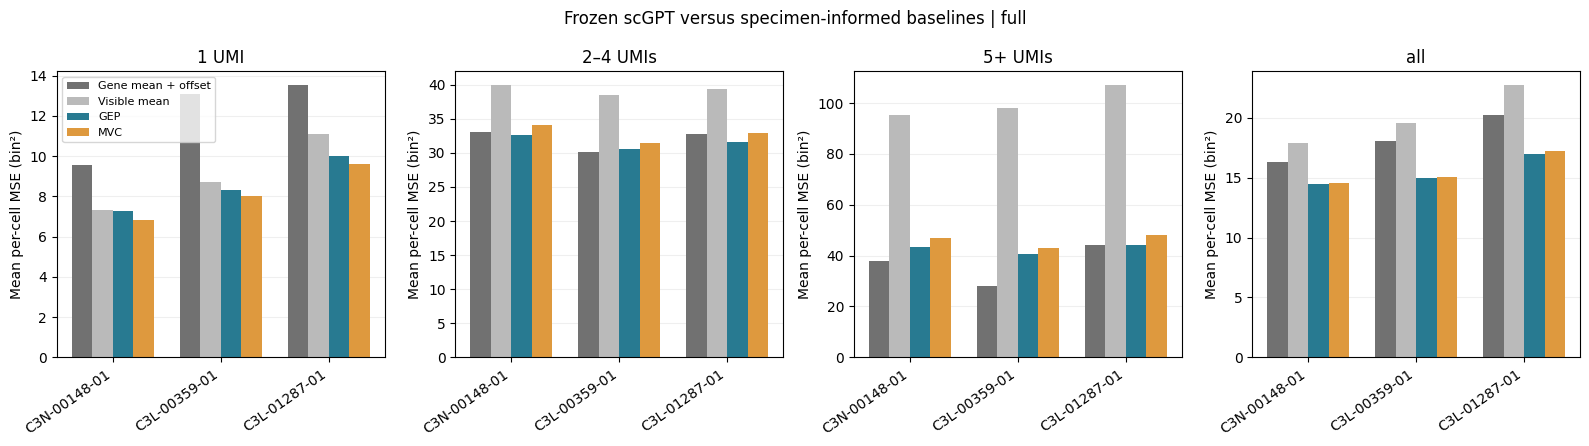

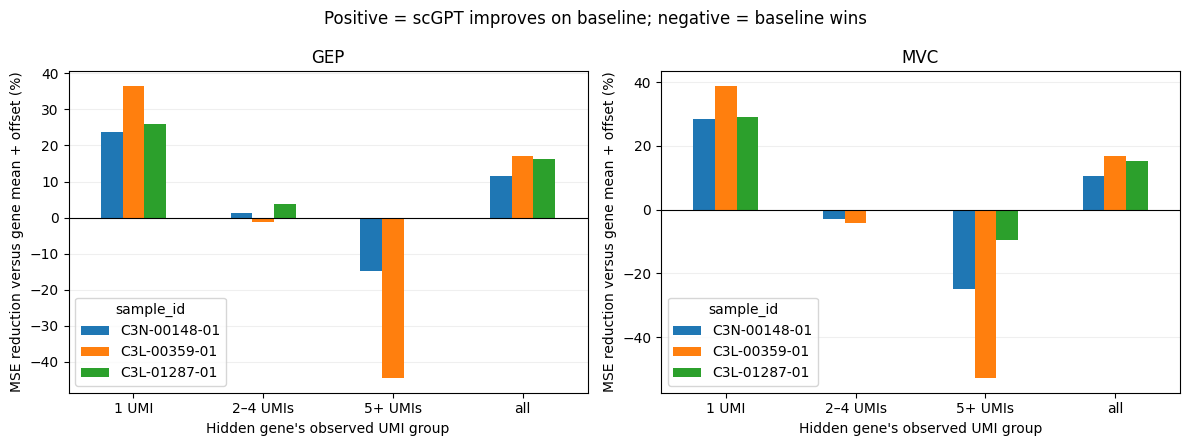

Figures: /home/akash1/scgpt-cna/multicase_expression/results/20261105T212842316783Z_full/figures


In [9]:
# 8 — Two compact report figures: native-bin loss and advantage over the strong baseline.
import matplotlib.pyplot as plt

figure_dir = RUN_DIR / "figures"
figure_dir.mkdir(exist_ok=True)
sample_order = list(dict.fromkeys(all_summary["sample_id"]))
methods = ["gene_mean_plus_offset", "visible_mean", "GEP", "MVC"]
colors = ["#717171", "#BABABA", "#287A91", "#DE993E"]
labels = ["Gene mean + offset", "Visible mean", "GEP", "MVC"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), squeeze=False)
for ax, group in zip(axes[0], COUNT_GROUPS):
    table = all_summary.loc[all_summary["count_group"].eq(group)].pivot(
        index="sample_id", columns="method", values="mean_MSE").reindex(index=sample_order, columns=methods)
    x = np.arange(len(sample_order))
    width = 0.19
    for k, (method, color, label) in enumerate(zip(methods, colors, labels)):
        ax.bar(x + (k - 1.5) * width, table[method], width, label=label, color=color)
    ax.set_title(group)
    ax.set_xticks(x, sample_order, rotation=35, ha="right")
    ax.set_ylabel("Mean per-cell MSE (bin²)")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"Frozen scGPT versus specimen-informed baselines | {MODE}")
fig.tight_layout()
fig.savefig(figure_dir / "mse_by_specimen_and_umi_group.png", dpi=200, bbox_inches="tight")
fig.savefig(figure_dir / "mse_by_specimen_and_umi_group.pdf", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), squeeze=False)
for ax, head in zip(axes[0], ["GEP", "MVC"]):
    table = all_summary.loc[all_summary["method"].eq(head)].pivot(
        index="count_group", columns="sample_id", values="percent_MSE_reduction"
    ).reindex(COUNT_GROUPS)
    table.reindex(columns=sample_order).plot.bar(ax=ax, rot=0)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(head)
    ax.set_xlabel("Hidden gene's observed UMI group")
    ax.set_ylabel("MSE reduction versus gene mean + offset (%)")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
fig.suptitle("Positive = scGPT improves on baseline; negative = baseline wins")
fig.tight_layout()
fig.savefig(figure_dir / "relative_gain_by_specimen.png", dpi=200, bbox_inches="tight")
fig.savefig(figure_dir / "relative_gain_by_specimen.pdf", bbox_inches="tight")
plt.show()
print("Figures:", figure_dir)
